# Forecasting with ARMA Models

<a href="https://colab.research.google.com/github/febse/ts2025/blob/main/05-ARMA-Fitting-Class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open Class Version In Colab"/>Class Version</a>


In [1]:
# A purely random process with a standard deviation of 1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import arma_generate_sample
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Model parameters
phi_1 = 0.8  # AR1 coefficient
phi_2 = 0 # set to -0.6 for AR(2) process with complex roots
theta_1 = 0  # MA coefficient (set to something non-zero for ARMA process. For a pure MA process, set phi_1=0 and phi_2=0 and theta_1 to somethig non-zero)
theta_2 = 0

sigma = 1  # standard deviation of the purely random process
n = 100

noise = arma_generate_sample(ar=[1], ma=[1], nsample=n, scale=sigma)

dt = arma_generate_sample(ar=[1, -phi_1, -phi_2], ma=[1, -theta_1, -theta_2], nsample=n, scale= 1.5 * sigma)

# Check the first 10 values of the generated time series
dt[:10]

array([ 1.59286523,  2.87658949, -1.36472061,  0.85083758,  0.12496889,
       -0.73535513, -0.73526928, -0.87041214,  1.62790052,  2.17166827])

## Fitting AR(p) Models

$$
x_t = \phi_0 + \phi_1 x_{t-1} + \phi_2 x_{t-2} + ... + \phi_p x_{t-p} + e_t
$$

where $e_t \sim N(0, \sigma_e^2), E(e_t e_{t-k}) = 0 \text{ for } k \neq 0$.

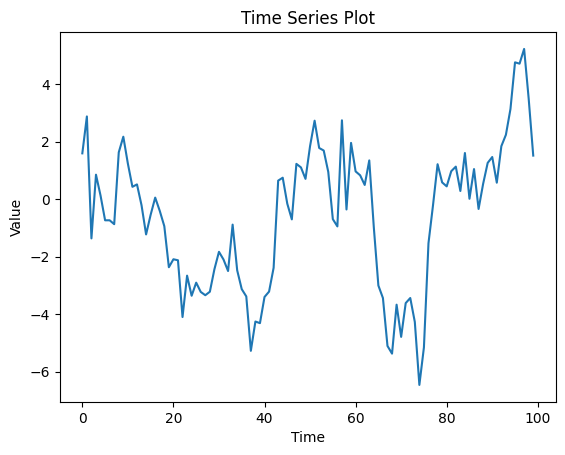

In [2]:
# Plot the series

plt.plot(dt)
plt.title('Time Series Plot')
plt.xlabel('Time')
plt.ylabel('Value')
plt.show()


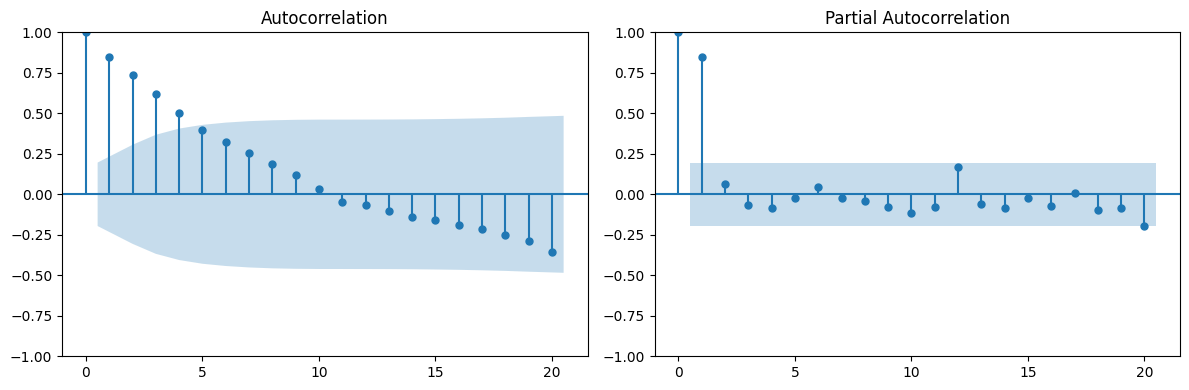

In [3]:
# Plot ACF and PACF

fix, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(dt, ax=ax[0], lags=20)
plot_pacf(dt, ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

In [4]:
# Use statsmodels to fit an AR(1) model and print the summary

from statsmodels.tsa.arima.model import ARIMA

model_ar1 = ARIMA(dt, order=(1, 0, 0))
model_ar1_fit = model_ar1.fit()

print(model_ar1_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  100
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -167.109
Date:                Wed, 18 Nov 2026   AIC                            340.218
Time:                        09:30:30   BIC                            348.034
Sample:                             0   HQIC                           343.381
                                - 100                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.3860      0.839     -0.460      0.645      -2.030       1.258
ar.L1          0.8522      0.051     16.554      0.000       0.751       0.953
sigma2         1.6345      0.216      7.556      0.0

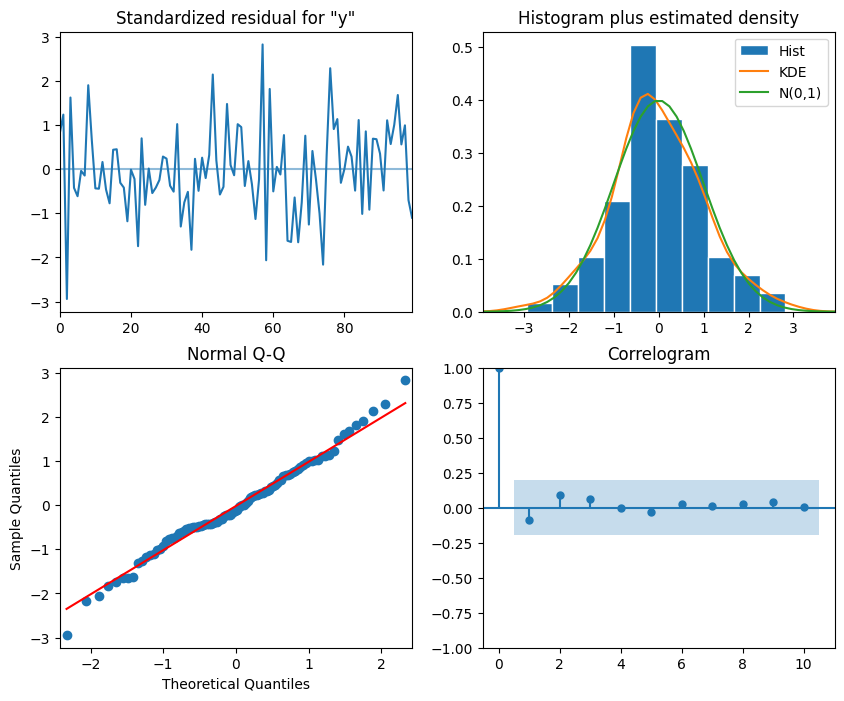

In [5]:
model_ar1_fit.plot_diagnostics(figsize=(10, 8))
plt.show()

## The Jung-Box Test

$$
Q=T(T+2)\sum _{k=1}^{h}{\frac {{\hat {\rho }}_{k}^{2}}{T-k}} \underset{H_0}{\sim} \chi(h)
$$

$$
\begin{align*}
H^{h}_0: & \rho_1 = \rho_2 = \ldots = \rho_{h} \\
H^{h}_1: & \text{ at least one of } \rho_k \neq 0, \quad k = 1,\ldots, h
\end{align*}
$$

In [6]:
lb_serial_corr = model_ar1_fit.test_serial_correlation("ljungbox")

for i, (stat, p) in enumerate(zip(lb_serial_corr[0][0], lb_serial_corr[0][1])):
    print(f"Lag {i + 1}, test statistic = {stat:.3f} with p-value {p:.3f}")

Lag 1, test statistic = 0.804 with p-value 0.370
Lag 2, test statistic = 1.659 with p-value 0.436
Lag 3, test statistic = 2.062 with p-value 0.560
Lag 4, test statistic = 2.062 with p-value 0.724
Lag 5, test statistic = 2.156 with p-value 0.827
Lag 6, test statistic = 2.237 with p-value 0.897
Lag 7, test statistic = 2.263 with p-value 0.944
Lag 8, test statistic = 2.355 with p-value 0.968
Lag 9, test statistic = 2.547 with p-value 0.980
Lag 10, test statistic = 2.553 with p-value 0.990


In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
resid = model_ar1_fit.resid

acorr_ljungbox(resid, lags=range(2, 11), model_df=1)

,lb_stat,lb_pvalue
2,1.101982,0.293832
3,1.657349,0.436628
4,1.659055,0.646075
5,1.776908,0.776704
6,1.855155,0.868802
7,1.878124,0.930559
8,2.078491,0.955369
9,2.315546,0.969778
10,2.318219,0.985379


In [8]:
forecast = model_ar1_fit.get_forecast(steps=2)

print("Forecasts")
print(forecast.predicted_mean)

print("Standard errors")
print(forecast.se_mean)

Forecasts
[1.23356129 0.99421832]
Standard errors
[1.27848306 1.6797716 ]


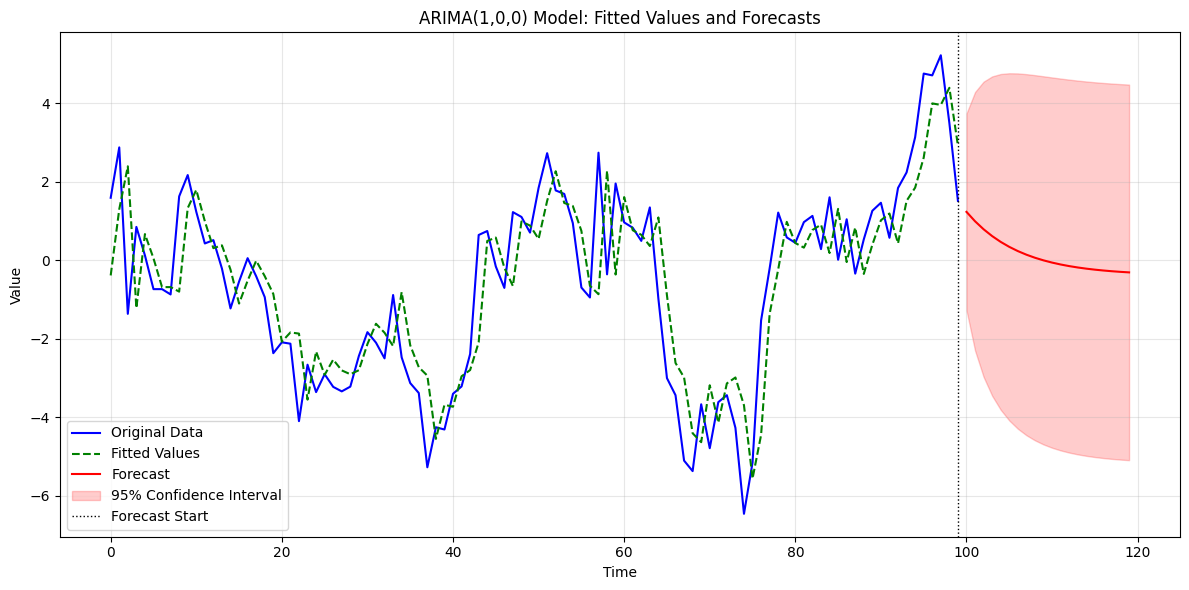

In [9]:
# Plot the prediction of the model

# Get in-sample fitted values
fitted_values = model_ar1_fit.fittedvalues

# Get out-of-sample forecasts (e.g., 20 steps ahead)
forecast_steps = 20
forecast = model_ar1_fit.forecast(steps=forecast_steps)
forecast_index = np.arange(len(dt), len(dt) + forecast_steps)

# Get forecast confidence intervals
forecast_result = model_ar1_fit.get_forecast(steps=forecast_steps)
forecast_ci = np.array(forecast_result.conf_int())  # Convert to numpy array

# Plot
plt.figure(figsize=(12, 6))
plt.plot(dt, label='Original Data', color='blue', linewidth=1.5)
plt.plot(fitted_values, label='Fitted Values', color='green', linewidth=1.5, linestyle='--')
plt.plot(forecast_index, forecast, label='Forecast', color='red', linewidth=1.5)
plt.fill_between(forecast_index, 
                 forecast_ci[:, 0],
                 forecast_ci[:, 1], 
                 color='red', alpha=0.2, label='95% Confidence Interval')
plt.axvline(x=len(dt)-1, color='black', linestyle=':', linewidth=1, label='Forecast Start')
plt.xlabel('Time')
plt.ylabel('Value')
plt.title('ARIMA(1,0,0) Model: Fitted Values and Forecasts')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Information Criteria

### Akaike Information Criterion (AIC)

$$
AIC = -2 \underbrace{\log(L)}_{\text{Goodness of fit}} + 2 \underbrace{(p + q + k + 1)}_{\text{number of parameters}}
$$


$$
AICc = AIC + \frac{2(p + q + k + 1)(p + q + k + 2)}{T - p - q - k - 2}
$$

$$
BIC = AIC + (\log(T) - 2)(p + q + k + 1)
$$

